# Modelling: predicting the number of Rings

A first model to predict the age (`Rings`) of an abalone. We compare a linear regression with a random forest, track every run with MLflow, register the best model in the MLflow Model Registry and use it to predict.

# Imports

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from mlflow import MlflowClient
from sklearn.base import RegressorMixin
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

DATA_PATH = "../data/abalone.csv"
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

# 1 - Load data

In [2]:
def load_data(path: str) -> pd.DataFrame:
    """Load the abalone dataset."""
    return pd.read_csv(path)


df = load_data(DATA_PATH)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
train_df.shape, test_df.shape

((3341, 9), (836, 9))

# 2 - Prepare the data

- Rename the columns to snake_case (`Whole weight` → `whole_weight`).
- One-hot encode `sex`. The encoder is fitted on the training set only, then reused on the test set.
- The target is `rings`.

In [6]:
def preprocess(
    df: pd.DataFrame, encoder: OneHotEncoder | None = None
) -> tuple[pd.DataFrame, pd.Series, OneHotEncoder]:
    """Return the features X, the target y and the fitted encoder."""
    df = df.rename(columns=lambda name: name.lower().replace(" ", "_"))
    if encoder is None:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        encoder.fit(df[["sex"]])
    sex_encoded = pd.DataFrame(
        encoder.transform(df[["sex"]]),
        columns=encoder.get_feature_names_out(),
        index=df.index,
    )
    X = pd.concat([df.drop(columns=["sex", "rings"]), sex_encoded], axis=1)
    y = df["rings"] if "rings" in df.columns else None
    return X, y, encoder


X_train, y_train, encoder = preprocess(train_df)
X_test, y_test, _ = preprocess(test_df, encoder)
X_train.head()

,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,sex_F,sex_I,sex_M
4038,0.550,0.445,0.125,0.6720,0.2880,0.1365,0.210,0.0,1.0,0.0
1272,0.475,0.355,0.100,0.5035,0.2535,0.0910,0.140,0.0,1.0,0.0
3384,0.305,0.225,0.070,0.1485,0.0585,0.0335,0.045,1.0,0.0,0.0
3160,0.275,0.200,0.065,0.1165,0.0565,0.0130,0.035,0.0,1.0,0.0
3894,0.495,0.380,0.135,0.6295,0.2630,0.1425,0.215,0.0,0.0,1.0


# 3 - Train and evaluate

In [7]:
def train_model(X: pd.DataFrame, y: pd.Series, model: RegressorMixin) -> RegressorMixin:
    """Fit a sklearn regressor."""
    return model.fit(X, y)


def predict(X: pd.DataFrame, model: RegressorMixin) -> np.ndarray:
    """Predict the number of rings."""
    return model.predict(X)


def evaluate_model(y_true: pd.Series, y_pred: np.ndarray) -> float:
    """Root mean squared error, in rings."""
    return root_mean_squared_error(y_true, y_pred)

# 4 - Track the experiments with MLflow

In [8]:
mlflow.set_tracking_uri((PROJECT_ROOT / "mlruns").as_uri())
print(f"tracking URI: '{mlflow.get_tracking_uri()}'")

tracking URI: 'file:///home/hitaishi/Documents/HEC/09_mlops/project/group14-xhec-mlops-2026-project/mlruns'


In [9]:
client = MlflowClient()

Each model is one run of the `abalone-rings` experiment, with its tags, parameters, train and test RMSE, and the fitted model.

In [10]:
mlflow.set_experiment("abalone-rings")

models = {
    "linear-regression": LinearRegression(),
    "random-forest": RandomForestRegressor(random_state=42),
}
model_uris = {}

for model_name, model in models.items():
    with mlflow.start_run(run_name=model_name) as run:
        mlflow.set_tags(
            {"model": model_name, "developer": "hitaishi", "dataset": "abalone"}
        )
        mlflow.log_params(model.get_params())

        model = train_model(X_train, y_train, model)
        mlflow.log_metric(
            "train-rmse", evaluate_model(y_train, predict(X_train, model))
        )
        mlflow.log_metric("test-rmse", evaluate_model(y_test, predict(X_test, model)))

        model_info = mlflow.sklearn.log_model(
            model,
            name="model",
            input_example=X_train.head(),
            skops_trusted_types=["sklearn.tree._tree.Tree"],
        )
        model_uris[run.info.run_id] = model_info.model_uri

2026/10/22 14:23:14 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/22 14:23:17 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


In [11]:
experiment = client.get_experiment_by_name("abalone-rings")
runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["metrics.`test-rmse` ASC"],
)
pd.DataFrame(
    [
        {
            "run_name": run.info.run_name,
            "train-rmse": run.data.metrics["train-rmse"],
            "test-rmse": run.data.metrics["test-rmse"],
        }
        for run in runs
    ]
)

,run_name,train-rmse,test-rmse
0,linear-regression,2.187202,2.211613
1,linear-regression,2.187202,2.211613
2,linear-regression,2.187202,2.211613
3,linear-regression,2.187202,2.211613
4,linear-regression,2.187202,2.211613
5,random-forest,0.792792,2.255956
6,random-forest,0.792792,2.255956
7,random-forest,0.792792,2.255956
8,random-forest,0.792792,2.255956
9,random-forest,0.792792,2.255956


In [ ]:
# To use the MLFlow UI, run: 
!MLFLOW_ALLOW_FILE_STORE=true OPENSSL_CONF=/dev/null uv run mlflow ui --host 0.0.0.0 --port 5002

Then open http://127.0.0.1:5002 

# 5 - Register the best model

The run with the lowest test RMSE goes to the Model Registry. Model stages (`Production`, `Staging`) are deprecated since MLflow 2.9, so we mark the version with the `production` alias instead.

In [12]:
best_run = runs[0]
print(
    f"Best run: {best_run.info.run_name} (test RMSE = {best_run.data.metrics['test-rmse']:.3f})"
)

result = mlflow.register_model(model_uris[best_run.info.run_id], "abalone_rings_model")
client.set_registered_model_alias(
    name="abalone_rings_model", alias="production", version=result.version
)

Best run: linear-regression (test RMSE = 2.212)


Registered model 'abalone_rings_model' already exists. Creating a new version of this model...
Created version '3' of model 'abalone_rings_model'.


# 6 - Predict with the production model

In [13]:
model = mlflow.sklearn.load_model("models:/abalone_rings_model@production")
y_pred = predict(X_test, model)

pd.DataFrame({"true rings": y_test, "predicted rings": y_pred.round(1)}).head()

,true rings,predicted rings
866,9,11.8
1483,8,10.2
599,16,14.0
1702,9,12.0
670,14,11.2


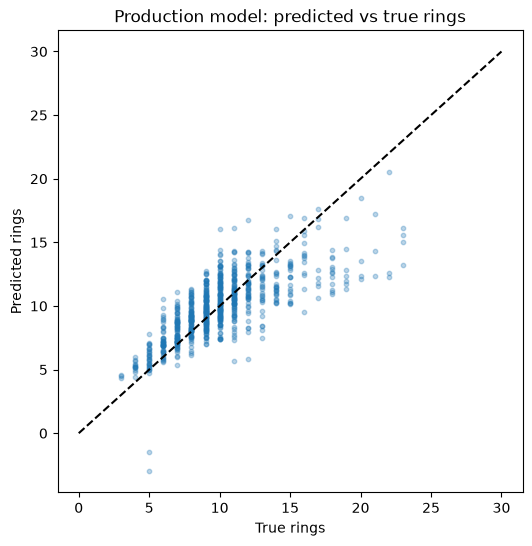

In [11]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred, alpha=0.3, s=10)
ax.plot([0, 30], [0, 30], color="black", linestyle="--")
ax.set_xlabel("True rings")
ax.set_ylabel("Predicted rings")
ax.set_title("Production model: predicted vs true rings")
plt.show()

# Conclusions

- **Linear regression is better than random forest**: test RMSE ≈ 2.21 rings, against ≈ 2.26 for the random forest with default parameters and ≈ 3.2 when always predicting the mean. The simpler model is both better and easier to explain. This model is used 
- **The random forest overfits**: its train RMSE (≈ 0.79) is far below its test RMSE, while the linear regression has similar train and test errors (≈ 2.19 and 2.21).
- **Model Registry**: the best run is registered as `abalone_rings_model` with the `production` alias, and the predictions above are made by loading it back from the registry.
- **Errors grow with age**: the model predicts young abalones well but underestimates the oldest ones, as expected from the EDA (size stops growing while rings keep adding up, and there are few old abalones).